# 06 — The FeedForward: ReLU and dropout

**Chapter 2** · suggested time: 25 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_2/06_feedforward.ipynb)

![Roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/00_roadmap.png)

After attention, each position has **received** information from its past: its vector is a weighted average of values. But a weighted average is still an almost **linear** operation. Now each position has to **process** what it received: combine clues, detect patterns ("after `q` comes `u`", "we are at the start of a speaker name"…). That is the job of the **FeedForward**.

**By the end of this notebook you will be able to:**
1. explain the FeedForward formula and the `C → 4C → C` widening;
2. show why a **non-linearity** (ReLU) is essential;
3. check that the FeedForward processes each position **separately**;
4. explain **dropout**, and the difference between `model.train()` and `model.eval()`.

In [1]:
# On Google Colab: fetch the course repo (corpora + shared modules such as minigpt.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("minigpt.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_2

In [2]:
# Setup: imports and the chapter's shared module
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # the minigpt.py file, next to this notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cu132 | device: cpu


## Recap
<img src="https://upload.wikimedia.org/wikipedia/commons/3/34/Transformer%2C_full_architecture.png" alt="Original encoder-decoder Transformer architecture" width="560" style="background:white"/>

*Illustration: dvgodoy, [Wikimedia Commons — Transformer, full architecture](https://commons.wikimedia.org/wiki/File:Transformer,_full_architecture.png), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/), reproduced without modification.*

## 1. The formula

In the paper (equation 2), for **each position** with vector $x \in \mathbb{R}^C$:

$$\text{FFN}(x) = \max(0,\ x W_1 + b_1)\, W_2 + b_2 \qquad W_1 \in \mathbb{R}^{C \times 4C},\quad W_2 \in \mathbb{R}^{4C \times C}$$

![FeedForward](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_2/figures/06_feedforward.png)

1. **Widen**: `Linear(C, 4C)` projects into a space 4 times larger, with room to detect many different patterns (each hidden neuron ≈ one detector).
2. **Non-linearity**: `ReLU(z) = max(0, z)` keeps only the "activated" detectors.
3. **Come back**: `Linear(4C, C)` recombines the activated detectors into a vector of size `C`, so it can be **added** to the residual stream (notebook 07).
4. **Dropout**: regularization (§5).

**Attention = communication between positions. FeedForward = computation inside each position.**

## 2. Why a non-linearity? Without it, two layers = one

Two linear layers in a row simplify: $(x W_1) W_2 = x (W_1 W_2)$. Stacking linear layers, however wide, **never** gives more than a single linear map. Let's check.

In [3]:
torch.manual_seed(0)
lin1, lin2 = nn.Linear(8, 32, bias=False), nn.Linear(32, 8, bias=False)
x = torch.randn(5, 8)

two_layers = lin2(lin1(x))
single = x @ (lin1.weight.T @ lin2.weight.T)              # W = W1 @ W2, of size (8, 8)
print("Linear∘Linear == a single Linear?", torch.allclose(two_layers, single, atol=1e-6))

with_relu = lin2(F.relu(lin1(x)))
print("Linear∘ReLU∘Linear == that Linear?", torch.allclose(with_relu, single, atol=1e-6))

Linear∘Linear == a single Linear? True
Linear∘ReLU∘Linear == that Linear? False


### Experiment: learning a non-linear function

Let's try to learn $y = \sin(3x)$ with two networks of the **same size**, one without an activation, the other with ReLU.

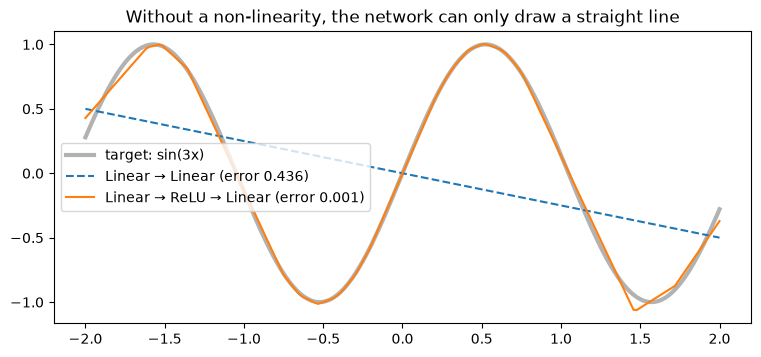

In [4]:
torch.manual_seed(0)
xs = torch.linspace(-2, 2, 200).unsqueeze(1)
ys = torch.sin(3 * xs)

def fit(net, steps=2000):
    opt = torch.optim.AdamW(net.parameters(), lr=1e-2)
    for _ in range(steps):
        loss = F.mse_loss(net(xs), ys)
        opt.zero_grad(); loss.backward(); opt.step()
    return loss.item()

without = nn.Sequential(nn.Linear(1, 64), nn.Linear(64, 1))
with_act = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 1))
l_without, l_with = fit(without), fit(with_act)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(xs, ys, "k", lw=3, alpha=.3, label="target: sin(3x)")
ax.plot(xs, without(xs).detach(), "--", label=f"Linear → Linear (error {l_without:.3f})")
ax.plot(xs, with_act(xs).detach(), label=f"Linear → ReLU → Linear (error {l_with:.3f})")
ax.legend(); ax.set_title("Without a non-linearity, the network can only draw a straight line"); plt.show()

The network with ReLU approximates the sine wave with **straight-line pieces**: each hidden neuron adds a "kink" where its input crosses zero. The more neurons, the more kinks you can make: that is the point of widening to `4C`.

## 3. ReLU

$$\text{ReLU}(z) = \max(0, z) \qquad \text{ReLU}'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$

- **Simple and fast**: one comparison.
- **Gradient not squashed**: when the neuron is active, the derivative is exactly 1 (unlike `tanh` or `sigmoid`, which saturate). This is what made it possible to train deep networks (Glorot et al., 2011).
- **Drawback**: a neuron whose input is always negative **no longer receives any gradient** (a "dead neuron"). Smoothed variants such as **GELU** (used by GPT-2 and BERT) keep a small gradient for negative values.

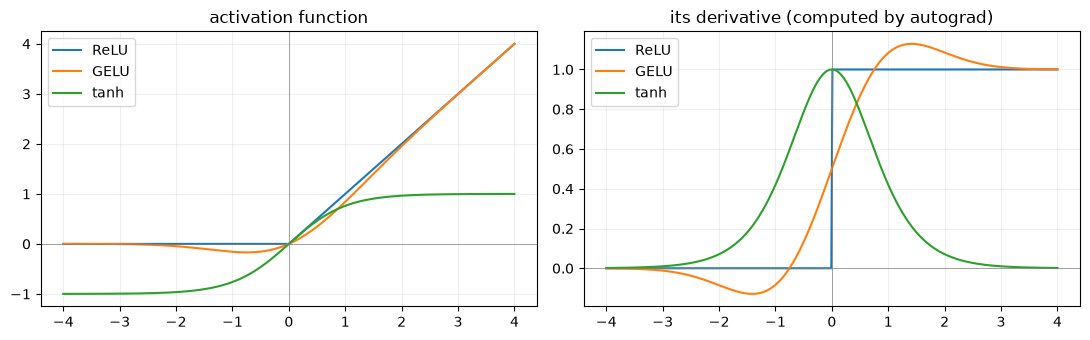

In [5]:
z = torch.linspace(-4, 4, 400, requires_grad=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, f in [("ReLU", F.relu), ("GELU", F.gelu), ("tanh", torch.tanh)]:
    y = f(z)
    g, = torch.autograd.grad(y.sum(), z)
    axes[0].plot(z.detach(), y.detach(), label=name)
    axes[1].plot(z.detach(), g, label=name)
axes[0].set_title("activation function"); axes[1].set_title("its derivative (computed by autograd)")
for ax in axes: ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 4. Each position is processed separately

`nn.Linear` applied to a `(B, T, C)` tensor acts on **the last axis only**: the same matrix is applied to each of the `B × T` vectors. Consequence: changing position 5 changes **only** the output at position 5. Let's compare with attention, where the change propagates to the following positions.

In [6]:
class FeedForward(nn.Module):
    """Small network applied independently at each position: C -> 4C -> ReLU -> C."""

    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


torch.manual_seed(0)
C = 16
ff = FeedForward(C, dropout=0.0)
att = minigpt.MultiHeadAttention(C, n_head=4, block_size=10, dropout=0.0)
x = torch.randn(1, 10, C)
x_mod = x.clone(); x_mod[0, 5] += 1.0              # we only touch position 5

for name, layer in [("FeedForward", ff), ("Attention", att)]:
    d = (layer(x) - layer(x_mod)).abs().amax(-1)[0]
    print(f"{name:12s} changed positions: {[t for t in range(10) if d[t] > 1e-6]}")
print("\nFeedForward: (B, T, C) =", tuple(x.shape), "->", tuple(ff.net[0](x).shape), "->", tuple(ff(x).shape))

FeedForward  changed positions: [5]


Attention    changed positions: [5, 6, 7, 8, 9]

FeedForward: (B, T, C) = (1, 10, 16) -> (1, 10, 64) -> (1, 10, 16)


- **FeedForward**: only position 5 changes → no communication between positions.
- **Attention**: positions 5 to 9 change (they "see" position 5), positions 0 to 4 do not (causal mask).

### The FeedForward is heavy

With `C = 64`: `Linear(64, 256)` + `Linear(256, 64)` ≈ 33,000 parameters, versus ≈ 16,600 for multi-head attention. The FeedForward holds **about two thirds** of a block's parameters. Interpretability work suggests it acts as a **key-value memory**: the rows of $W_1$ detect patterns, those of $W_2$ write the associated information (Geva et al., 2021).

In [7]:
C = 64
print("FeedForward:", minigpt.count_parameters(minigpt.FeedForward(C, 0.0)))
print("Attention:  ", minigpt.count_parameters(minigpt.MultiHeadAttention(C, 4, 64, 0.0)))

FeedForward: 33088
Attention:   16448


---
## 5. Dropout

Our model has hundreds of thousands of parameters; Shakespeare has a million characters. A large enough network can **memorize** the training data instead of extracting rules from it: that is **overfitting**.

**Dropout** (Srivastava et al., 2014): during training, at each pass, we **set each value to zero with probability `p`**, at random. The network can no longer rely on one specific neuron: it has to spread the information out and becomes more robust. You can see it as training a large number of different sub-networks that share their weights.

**Two important details:**
1. The values that are kept are **multiplied by `1/(1−p)`**, so the mean does not change.
2. Dropout is active **only in training mode** (`model.train()`). In evaluation and generation (`model.eval()`), it does **nothing**.

In [8]:
torch.manual_seed(0)
drop = nn.Dropout(p=0.2)
x = torch.ones(2, 10)

drop.train()
y = drop(x)
print("train mode:\n", y)
print(f"fraction of zeros: {(y == 0).float().mean():.2f}  | kept values: {1 / (1 - 0.2):.2f} = 1/(1-p)")
print("mean over 100,000 values:", drop(torch.ones(100_000)).mean().item())

drop.eval()
print("\neval mode:\n", drop(x))

train mode:
 tensor([[0.0000, 1.2500, 1.2500, 0.0000, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500,
         1.2500],
        [1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500, 1.2500,
         1.2500]])
fraction of zeros: 0.10  | kept values: 1.25 = 1/(1-p)


mean over 100,000 values: 0.9991875290870667

eval mode:
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


In [9]:
# Practical consequence: in train mode, two identical passes give two different results.
torch.manual_seed(0)
ff = minigpt.FeedForward(16, dropout=0.2)
x = torch.randn(1, 3, 16)
ff.train(); print("train: same outputs?", torch.equal(ff(x), ff(x)))
ff.eval();  print("eval:  same outputs?", torch.equal(ff(x), ff(x)))

train: same outputs? False
eval:  same outputs? True


**Where is [dropout](https://gebob19.github.io/assets/dropout/dattn.pdf) in our GPT?** In three places, with `p = 0.2` by default:
1. on the **attention weights** of each head (a position randomly "forgets" some sources);
2. after the **projection** of multi-head attention;
3. at the end of the **FeedForward**.

That is why `estimate_loss` (notebook 09) calls `model.eval()` before measuring, then `model.train()` afterwards.

## Summary

- **FeedForward** = `Linear(C, 4C) → ReLU → Linear(4C, C) → Dropout`, applied **independently at each position**. Shape preserved: `(B, T, C)`.
- Without a **non-linearity**, stacking linear layers is pointless: they collapse into a single one.
- **ReLU**: simple, gradient of 1 when active; GELU is a smoothed version of it.
- **Dropout**: random zeros (probability `p`) + multiplication by `1/(1−p)`, only in `train()`. It fights overfitting.

**Check your understanding**
1. Why must the FeedForward come back to `C` channels at its output?
2. Does changing the character at position 3 change the FeedForward output at position 4? And the attention output?
3. Why is it essential to switch to `model.eval()` before generating text?

**Next → 07:** we have all the pieces of a block. How do they fit together, and how does the gradient flow through them?

### References
- Vaswani et al., [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), NeurIPS 2017 — §3.3, equation (2).
- V. Nair & G. Hinton, [*Rectified Linear Units Improve Restricted Boltzmann Machines*](https://www.cs.toronto.edu/~hinton/absps/reluICML.pdf), ICML 2010.
- X. Glorot, A. Bordes, Y. Bengio, [*Deep Sparse Rectifier Neural Networks*](https://proceedings.mlr.press/v15/glorot11a.html), AISTATS 2011.
- D. Hendrycks & K. Gimpel, [*Gaussian Error Linear Units (GELUs)*](https://arxiv.org/abs/1606.08415), 2016.
- N. Srivastava et al., [*Dropout: A Simple Way to Prevent Neural Networks from Overfitting*](https://jmlr.org/papers/v15/srivastava14a.html), JMLR 2014.
- M. Geva et al., [*Transformer Feed-Forward Layers Are Key-Value Memories*](https://arxiv.org/abs/2012.14913), EMNLP 2021.